# Pose training notebook

Joint vision and matched-pair pose training, following the original notebook's
cell layout, inline training loop, history names, plots and optional resume.
Training uses the same loss terms and default weights as the current `train_pose.py`.


In [6]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import os
import random
import time
import torch.nn.functional as F

from dataset import SceneTwoPairsDataset
from augmentations import build_train_transform, build_eval_transform
from colmap_pair_dataset import ColmapPairDataset
from model import PairImageCylinderModel
from losses import (
    vision_loss,
    patch_correspondence_loss,
    relative_depth_structure_loss,
    matched_depth_delta_loss,
    masked_relative_pose_loss_2d,
    )
from metrics import pose_errors, relative_pose_vector_errors, relative_cylinder_errors
from debugger import bug_check, debug_sinkhorn_matching
from debug_tests import evaluate_train_geometry, evaluate_16_correspondences,test_ransac_geometry_ablation_gt_coarse, test_matched_depth_consistency
from utils import plot_estimated_cylinders_on_images, plot_relative_pose, pose_to_text



In [25]:
# -----------------------------------------------------------------------------
# Configuration
# -----------------------------------------------------------------------------

BATCH_SIZE = 32 # 16
NUM_EPOCHS = 200
RESUME_TRAINING = False
SEED = 0
NUM_WORKERS = 4

PATCH_SIZE=(16, 4) # <-- 8 -> 4

VAL_INTERVAL = 10
LEARNING_RATE = 5e-5

NUM_BINS = 128 #256

# Checkpoint settings
BEST_MODEL_PATH = "best_joint_pose.pt"
LATEST_MODEL_PATH = "latest_joint_pose.pt"
# Choose which trained weights to use for test/inference: "best" or "latest".
INFERENCE_MODEL = "latest" # "best"

# Forest controls
FOREST_ENABLED = False
FOREST_START_EPOCH = 310

# Loss settings
LAMBDA_OCC = 10.0
LAMBDA_RADIUS = 10.0
LAMBDA_RAD = 10.0
LAMBDA_REPROJ = 1.0
LAMBDA_FOREST_SPARSITY = 0.1
OCC_THRESH = 0.5
LAMBDA_CORR = 1.0
LAMBDA_POSE = 2.0
LAMBDA_DEPTH_DELTA = 0.35
LAMBDA_WIDTH = 0.1

# Visualization settings
INFERENCE_BATCH_SIZE = 4
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
FOREST_SAMPLE_IDX = 0
FOREST_OCC_THRESHOLD = 0.3
VISION_SAMPLE_IDX = 0

# Saved with checkpoints so the inference scripts can reconstruct the model.
CHECKPOINT_CONFIG = dict(
    data_dir=".", epochs=NUM_EPOCHS, batch_size=BATCH_SIZE,
    lr=LEARNING_RATE, val_interval=VAL_INTERVAL, num_workers=NUM_WORKERS,
    seed=SEED, img_size=128, patch_size=PATCH_SIZE, embed_dim=192,
    depth=4, num_heads=4, num_bins=NUM_BINS, dropout=0.1,
    lambda_occ=LAMBDA_OCC, lambda_radius=LAMBDA_RADIUS,
    occ_thresh=OCC_THRESH, lambda_corr=LAMBDA_CORR,
    lambda_depth_delta=LAMBDA_DEPTH_DELTA, lambda_pose=LAMBDA_POSE,
    lambda_width=LAMBDA_WIDTH,
)


In [8]:
# Device and model
device = "cuda" if torch.cuda.is_available() else "cpu"
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
print("Seed:", SEED)

torch.set_float32_matmul_precision("high")
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

if device == "cuda":
    torch.backends.cudnn.benchmark = True

model = PairImageCylinderModel(
    img_size=128,
    patch_size=PATCH_SIZE,
    in_chans=3,
    embed_dim=192,
    depth=4,
    num_heads=4,
    num_bins=NUM_BINS,
    dropout=0.1,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,} ({n_params / 1e6:.2f}M)")

# Keep normal model for checkpoint loading/saving
raw_model = model

# Variable-length GT matches: use eager mode for this model.

optimizer = torch.optim.AdamW( model.parameters(), lr=LEARNING_RATE, weight_decay=0.05, )


CUDA available: True
NVIDIA GeForce RTX 5050 Laptop GPU
Seed: 0
Model parameters: 4,363,209 (4.36M)


In [9]:
START_EPOCH = 0
resume_checkpoint = None

if RESUME_TRAINING and os.path.exists(LATEST_MODEL_PATH):
    resume_checkpoint = torch.load(
        LATEST_MODEL_PATH,
        map_location=device,
        weights_only=False,
    )

    raw_model.load_state_dict(resume_checkpoint["model_state_dict"])

    optimizer.load_state_dict(resume_checkpoint["optimizer_state_dict"])

    if "scaler_state_dict" in resume_checkpoint:
        scaler.load_state_dict(resume_checkpoint["scaler_state_dict"])
    START_EPOCH = resume_checkpoint["epoch"]

    print(f"Resuming training from epoch {START_EPOCH}")
else:
    print("Starting training from scratch")

Starting training from scratch


## Data

Training and validation data are always available. The forest loader is created only when `FOREST_ENABLED=True`.


In [10]:
train_dataset = SceneTwoPairsDataset(
    root_dir="dataset",
    image_size=128,
    debug=False,
    return_two_pairs=False,
    transform=build_train_transform(128),
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device == "cuda"),
    persistent_workers=(NUM_WORKERS > 0))

val_dataset = SceneTwoPairsDataset(
    root_dir="valdataset",
    image_size=128,
    debug=False,
    return_two_pairs=False,
    transform=build_eval_transform(128),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device == "cuda"),
    persistent_workers=(NUM_WORKERS > 0))

forest_loader = None
if FOREST_ENABLED:
    forest_dataset = ColmapPairDataset( dataset_dir="forestdataset_torpa", image_size=128, )
    forest_loader = DataLoader( forest_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, )

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
if FOREST_ENABLED:
    print("Forest batches:", len(forest_loader))


Train batches: 155
Val batches: 16


## Optional debug checks

Run these only when needed. They do not affect training.


In [11]:
# bug_check(0)
# debug_sinkhorn_matching(device=device)

In [12]:
def validate():
    model.eval()

    totals = {
        "total": 0.0,
        "vision": 0.0,
        "vision_occupancy": 0.0,
        "vision_radius": 0.0,
        "vision_depth": 0.0,
        "vision_width": 0.0,
        "correspondence": 0.0,
        "depth_structure": 0.0,
        "depth_delta": 0.0,
        "pose": 0.0,
        "translation": 0.0,
        "rotation": 0.0,
        "cylinder_radius_rel_l2": 0.0,
        "cylinder_position_rel_l2": 0.0,
    }

    num_batches = 0

    with torch.no_grad():
        for batch in val_loader:
            img_a, vision_a, img_b, vision_b, pose_ab = tuple(
                x.to(device, non_blocking=True) for x in batch
            )

            pred_vision_a, pred_vision_b, pred_pose, corr_a, corr_b, pose_info = model(
                img_a,
                img_b,
                return_corr=True,
                compute_pose=(LAMBDA_POSE != 0),
                target_vision_a=vision_a,
                target_vision_b=vision_b,
                return_pose_inputs=True,
                occ_thresh=OCC_THRESH,
            )

            vis_a, occ_a, rad_a, dep_a, width_a = vision_loss(pred_vision_a, vision_a, occ_thresh=OCC_THRESH, lambda_occ=LAMBDA_OCC,
                lambda_radius=LAMBDA_RADIUS, lambda_depth=1.0, lambda_width=LAMBDA_WIDTH)
            vis_b, occ_b, rad_b, dep_b, width_b = vision_loss(pred_vision_b, vision_b, occ_thresh=OCC_THRESH, lambda_occ=LAMBDA_OCC,
                lambda_radius=LAMBDA_RADIUS, lambda_depth=1.0, lambda_width=LAMBDA_WIDTH)

            vision_loss_total = 0.5 * (vis_a + vis_b)

            corr_loss = patch_correspondence_loss(corr_a, vision_a, corr_b, vision_b)

            depth_structure_loss = 0.5 * (
                relative_depth_structure_loss(pred_vision_a, vision_a, OCC_THRESH)
                +
                relative_depth_structure_loss(pred_vision_b, vision_b, OCC_THRESH)
            )

            depth_delta_loss = matched_depth_delta_loss(pred_vision_a, vision_a, pred_vision_b, vision_b, OCC_THRESH)
            
            if LAMBDA_POSE != 0:
                pose_total, t_loss, r_loss = masked_relative_pose_loss_2d(
                    pred_pose, pose_ab, pose_info["pose_valid"],
                    t_weight=1.0, r_weight=1.0,
                )
            else:
                pose_total = vision_loss_total.new_zeros(())
                t_loss = vision_loss_total.new_zeros(())
                r_loss = vision_loss_total.new_zeros(())

            total_loss = (
                vision_loss_total
                + LAMBDA_CORR * corr_loss
                + 0.5 * depth_structure_loss
                + LAMBDA_DEPTH_DELTA * depth_delta_loss
                + LAMBDA_POSE * pose_total
            )

            # Cylinder geometry diagnostics
            radius_a, position_a = relative_cylinder_errors(
                pred_vision_a, vision_a, OCC_THRESH
            )
            radius_b, position_b = relative_cylinder_errors(
                pred_vision_b, vision_b, OCC_THRESH
            )

            totals["cylinder_radius_rel_l2"] += (
                0.5 * (radius_a + radius_b)
            ).item()

            totals["cylinder_position_rel_l2"] += (
                0.5 * (position_a + position_b)
            ).item()

            totals["total"] += total_loss.item()
            totals["vision"] += vision_loss_total.item()
            totals["vision_occupancy"] += (0.5 * (occ_a + occ_b)).item()
            totals["vision_radius"] += (0.5 * (rad_a + rad_b)).item()
            totals["vision_depth"] += (0.5 * (dep_a + dep_b)).item()
            totals["vision_width"] += (0.5 * (width_a + width_b)).item()
            totals["correspondence"] += corr_loss.item()
            totals["depth_structure"] += depth_structure_loss.item()
            totals["depth_delta"] += depth_delta_loss.item()
            totals["pose"] += pose_total.item()
            totals["translation"] += t_loss.item()
            totals["rotation"] += r_loss.item()

            num_batches += 1

    if num_batches == 0:
        raise RuntimeError("Validation loader is empty.")

    metrics = {
        key: value / num_batches
        for key, value in totals.items()
    }

    return metrics

## Training

In [13]:
if resume_checkpoint is not None:
    history = resume_checkpoint["history"]
    if "pose" not in history or "val_pose" not in history:
        raise ValueError("Resume requires a checkpoint from this joint notebook version.")

    best_val_loss = resume_checkpoint.get(
        "best_val_loss", float("inf")
    )
    best_epoch = resume_checkpoint.get(
        "best_epoch", None
    )

    print(f"Continuing history from epoch {START_EPOCH}")

else:
    history = {
        # Train
        "epoch": [],
        "total": [],
        "vision": [],
        "correspondence": [],
        "depth_structure": [],
        "depth_delta": [],
        "pose": [],
        "translation": [],
        "rotation": [],

        # Forest - behålls
        "forest_epoch": [],
        "forest_total": [],
        "forest_radius_consistency": [],
        "forest_reprojection": [],
        "forest_sparsity": [],

        # Validation
        "val_epoch": [],
        "val_total": [],
        "val_vision": [],
        "val_correspondence": [],
        "val_depth_structure": [],
        "val_depth_delta": [],
        "val_pose": [],
        "val_translation": [],
        "val_rotation": [],

        # Geometry diagnostics
        "val_cylinder_radius_rel_l2": [],
        "val_cylinder_position_rel_l2": [],
    }

    best_val_loss = float("inf")
    best_epoch = None

# Diagnostic-only history. Earlier checkpoints do not contain these values.
# Preserve epoch alignment with NaN; no earlier losses are reconstructed.
VISION_COMPONENT_WEIGHTS = {
    "vision_occupancy": LAMBDA_OCC,
    "vision_radius": LAMBDA_RADIUS,
    "vision_depth": 1.0,
    "vision_width": LAMBDA_WIDTH,
}
for component in VISION_COMPONENT_WEIGHTS:
    for prefix, epoch_key in (("", "epoch"), ("val_", "val_epoch")):
        for suffix in ("", "_weighted"):
            key = prefix + component + suffix
            values = history.setdefault(key, [])
            if len(values) > len(history[epoch_key]):
                raise ValueError(f"History length mismatch: {key}")
            values.extend([float("nan")] * (len(history[epoch_key]) - len(values)))

for epoch in range(START_EPOCH, NUM_EPOCHS):
    epoch_num = epoch + 1
    epoch_start = time.perf_counter()
    model.train()
    forest_active = False
    train_totals = {
        "total": 0.0,
        "vision": 0.0,
        "vision_occupancy": 0.0,
        "vision_radius": 0.0,
        "vision_depth": 0.0,
        "vision_width": 0.0,
        "correspondence": 0.0,
        "depth_structure": 0.0,
        "depth_delta": 0.0,
        "pose": 0.0,
        "translation": 0.0,
        "rotation": 0.0,
    }

    forest_totals = {
        "total": 0.0,
        "radius_consistency": 0.0,
        "reprojection": 0.0,
        "sparsity": 0.0,
    }
    for batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        (
            img_a,
            vision_a,
            img_b,
            vision_b,
            pose_ab,
        ) = tuple(x.to(device, non_blocking=True) for x in batch)
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device == "cuda"),
        ):
            # Forward
            pred_vision_a, pred_vision_b, pred_pose, corr_a, corr_b, pose_info = model(
                img_a,
                img_b,
                return_corr=True,
                compute_pose=(LAMBDA_POSE != 0),
                target_vision_a=vision_a,
                target_vision_b=vision_b,
                return_pose_inputs=True,
                occ_thresh=OCC_THRESH,
            )
            
            # Correspondence loss
            corr_loss = patch_correspondence_loss(corr_a, vision_a, corr_b, vision_b)

            vis_a, occ_a, rad_a, dep_a, width_a = vision_loss(pred_vision_a, vision_a, occ_thresh=OCC_THRESH, lambda_occ=LAMBDA_OCC,
                lambda_radius=LAMBDA_RADIUS, lambda_depth=1.0, lambda_width=LAMBDA_WIDTH)

            vis_b, occ_b, rad_b, dep_b, width_b = vision_loss(pred_vision_b, vision_b, occ_thresh=OCC_THRESH, lambda_occ=LAMBDA_OCC,
                lambda_radius=LAMBDA_RADIUS, lambda_depth=1.0, lambda_width=LAMBDA_WIDTH)

            vision_loss_total = 0.5 * (vis_a + vis_b)
            
            depth_structure_loss = 0.5 * (relative_depth_structure_loss(pred_vision_a, vision_a, OCC_THRESH)
                + relative_depth_structure_loss(pred_vision_b, vision_b, OCC_THRESH))

            depth_delta_loss = matched_depth_delta_loss(pred_vision_a, vision_a, pred_vision_b, vision_b, OCC_THRESH)
            
            if LAMBDA_POSE != 0:
                pose_total, t_loss, r_loss = masked_relative_pose_loss_2d(
                    pred_pose, pose_ab, pose_info["pose_valid"],
                    t_weight=1.0, r_weight=1.0,
                )
            else:
                pose_total = vision_loss_total.new_zeros(())
                t_loss = vision_loss_total.new_zeros(())
                r_loss = vision_loss_total.new_zeros(())

            loss = (
                vision_loss_total
                + LAMBDA_CORR * corr_loss
                + 0.5 * depth_structure_loss
                + LAMBDA_DEPTH_DELTA * depth_delta_loss
                + LAMBDA_POSE * pose_total
            )

        # Backward
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        # Metrics
        train_totals["total"] += loss.item()
        train_totals["vision"] += vision_loss_total.item()
        train_totals["vision_occupancy"] += (0.5 * (occ_a + occ_b)).item()
        train_totals["vision_radius"] += (0.5 * (rad_a + rad_b)).item()
        train_totals["vision_depth"] += (0.5 * (dep_a + dep_b)).item()
        train_totals["vision_width"] += (0.5 * (width_a + width_b)).item()
        train_totals["correspondence"] += corr_loss.item()
        train_totals["depth_structure"] += depth_structure_loss.item()
        train_totals["depth_delta"] += depth_delta_loss.item()
        train_totals["pose"] += pose_total.item()
        train_totals["translation"] += t_loss.item()
        train_totals["rotation"] += r_loss.item()
    # Epoch metrics
    train_metrics = {
        key: value / len(train_loader)
        for key, value in train_totals.items()
    }

    history["epoch"].append(epoch_num)
    history["total"].append(train_metrics["total"])
    history["vision"].append(train_metrics["vision"])
    for component, weight in VISION_COMPONENT_WEIGHTS.items():
        history[component].append(train_metrics[component])
        history[component + "_weighted"].append(weight * train_metrics[component])
    history["correspondence"].append(train_metrics["correspondence"])
    history["depth_structure"].append(train_metrics["depth_structure"])
    history["depth_delta"].append(train_metrics["depth_delta"])
    history["pose"].append(train_metrics["pose"])
    history["translation"].append(train_metrics["translation"])
    history["rotation"].append(train_metrics["rotation"])
    
    log = (
        f"Epoch {epoch_num}: "
        f"tot={train_metrics['total']:.4f} | "
        f"vis={train_metrics['vision']:.4f} | "
        f"occ={train_metrics['vision_occupancy']:.4f} | "
        f"rad={train_metrics['vision_radius']:.4f} | "
        f"depth={train_metrics['vision_depth']:.4f} | "
        f"width={train_metrics['vision_width']:.4f} | "
        f"corr={train_metrics['correspondence']:.4f} | "
        f"struct={train_metrics['depth_structure']:.4f} | "
        f"delta={train_metrics['depth_delta']:.4f} | "
        f"pose={train_metrics['pose']:.4f} | "
    )
    # Validation
    if epoch_num == 1 or epoch_num % VAL_INTERVAL == 0:
        val_metrics = validate()

        history["val_epoch"].append(epoch_num)
        history["val_total"].append(val_metrics["total"])
        history["val_vision"].append(val_metrics["vision"])
        for component, weight in VISION_COMPONENT_WEIGHTS.items():
            history["val_" + component].append(val_metrics[component])
            history["val_" + component + "_weighted"].append(weight * val_metrics[component])
        history["val_correspondence"].append(val_metrics["correspondence"])
        history["val_depth_structure"].append(val_metrics["depth_structure"])
        history["val_depth_delta"].append(val_metrics["depth_delta"])
        history["val_pose"].append(val_metrics["pose"])
        history["val_translation"].append(val_metrics["translation"])
        history["val_rotation"].append(val_metrics["rotation"])
        history["val_cylinder_radius_rel_l2"].append(val_metrics["cylinder_radius_rel_l2"])
        history["val_cylinder_position_rel_l2"].append(val_metrics["cylinder_position_rel_l2"])

        is_best_total = val_metrics["total"] < best_val_loss

        if is_best_total:
            best_val_loss = val_metrics["total"]
            best_epoch = epoch_num

            torch.save(
                {
                    "epoch": epoch_num,
                    "model_state_dict": raw_model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "args": CHECKPOINT_CONFIG,
                    "history": history,
                    "best_val_loss": best_val_loss,
                    "best_epoch": best_epoch,
                },
                BEST_MODEL_PATH,
            )

        log += (
            f" | val_tot={val_metrics['total']:.4f}"
            f" | val_vis={val_metrics['vision']:.4f}"
            f" | val_occ={val_metrics['vision_occupancy']:.4f}"
            f" | val_rad={val_metrics['vision_radius']:.4f}"
            f" | val_depth={val_metrics['vision_depth']:.4f}"
            f" | val_width={val_metrics['vision_width']:.4f}"
            f" | val_corr={val_metrics['correspondence']:.4f}"
            f" | val_struct={val_metrics['depth_structure']:.4f}"
            f" | val_delta={val_metrics['depth_delta']:.4f}"
            f" | val_pose={val_metrics['pose']:.4f}"
        )

        if is_best_total:
            log += " | BEST TOTAL"
    # Latest checkpoint
    torch.save(
        {
            "epoch": epoch_num,
            "model_state_dict": raw_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "args": CHECKPOINT_CONFIG,
            "best_val_loss": best_val_loss,
            "best_epoch": best_epoch,
            "history": history,
        },
        LATEST_MODEL_PATH,
    )
    if epoch_num in (10, 20):
        epoch_path = Path(LATEST_MODEL_PATH).with_name(f"epoch_{epoch_num:03d}.pt")
        torch.save(
            {"epoch": epoch_num, "model_state_dict": raw_model.state_dict(),
             "optimizer_state_dict": optimizer.state_dict(),
             "scaler_state_dict": scaler.state_dict(), "args": CHECKPOINT_CONFIG,
             "history": history, "best_val_loss": best_val_loss,
             "best_epoch": best_epoch}, epoch_path,
        )
    log += f" | time={time.perf_counter() - epoch_start:.1f}s"
    print(log)
latest_model_state_dict = {key: value.detach().cpu().clone()
    for key, value in raw_model.state_dict().items()}
print(f"Best total: {best_val_loss:.6f} "f"at epoch {best_epoch}")
print(f"Latest model and history saved to: "f"{LATEST_MODEL_PATH}")

Epoch 1: tot=17.4003 | vis=10.3877 | occ=0.3127 | rad=0.1527 | depth=5.0889 | width=6.4402 | corr=2.7562 | struct=4.9135 | delta=0.4165 | pose=0.8269 |  | val_tot=16.2073 | val_vis=9.5249 | val_occ=0.3047 | val_rad=0.1370 | val_depth=4.6160 | val_width=4.9153 | val_corr=2.7409 | val_struct=4.9396 | val_delta=0.2103 | val_pose=0.6990 | BEST TOTAL | time=70.6s
Epoch 2: tot=16.0347 | vis=9.4177 | occ=0.2985 | rad=0.1386 | depth=4.5774 | width=4.6999 | corr=2.7433 | struct=4.8792 | delta=0.3188 | pose=0.6613 |  | time=64.8s
Epoch 3: tot=15.9007 | vis=9.3746 | occ=0.2977 | rad=0.1384 | depth=4.5558 | width=4.5800 | corr=2.7390 | struct=4.8512 | delta=0.2835 | pose=0.6312 |  | time=64.6s
Epoch 4: tot=15.4107 | vis=9.2108 | occ=0.2946 | rad=0.1386 | depth=4.4232 | width=4.5581 | corr=2.7265 | struct=4.7759 | delta=0.3839 | pose=0.4756 |  | time=64.9s
Epoch 5: tot=14.9540 | vis=8.9547 | occ=0.2851 | rad=0.1386 | depth=4.2620 | width=4.5614 | corr=2.4965 | struct=4.6194 | delta=0.6216 | pose=0.

## Load saved training state

Load the latest model and training history so the plots can be recreated after restarting VS Code.


In [14]:
latest_checkpoint_path = Path(LATEST_MODEL_PATH)
best_checkpoint_path = Path(BEST_MODEL_PATH)
checkpoint_path = best_checkpoint_path  # eller välj latest om den finns

if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

    # Checkpointen sparades från den okompilerade modellen.
    target_model = model._orig_mod if hasattr(model, "_orig_mod") else model
    target_model.load_state_dict(checkpoint["model_state_dict"])

    history = checkpoint["history"]
    best_val_loss = checkpoint.get("best_val_loss", float("inf"))
    best_epoch = checkpoint.get("best_epoch", checkpoint.get("epoch"))

    latest_model_state_dict = {
        key: value.detach().cpu().clone()
        for key, value in target_model.state_dict().items()
    }

    print(
        f"Loaded saved model and history from epoch {checkpoint['epoch']} "
        f"({checkpoint_path})"
    )
else:
    print(
        f"No saved checkpoint found at "
        f"{latest_checkpoint_path} or {best_checkpoint_path}."
    )

Loaded saved model and history from epoch 130 (best_joint_pose.pt)


In [15]:
if False:
    val_epochs = np.array(history["val_epoch"])

    plt.figure(figsize=(10, 5))
    plt.plot(val_epochs, history["val_cylinder_radius_rel_l2"], ".-", label="Cylinder radius")
    plt.plot(val_epochs, history["val_cylinder_position_rel_l2"], ".-", label="Cylinder position")
    plt.plot(val_epochs, history["val_camera_translation_rel_l2"], ".-", label="Camera translation")
    plt.plot(val_epochs, history["val_camera_rotation_rel_l2"], ".-", label="Camera rotation")
    plt.axhline(1.0, linestyle=":", alpha=0.4, label="relative error = 1")
    plt.xlabel("Epoch")
    plt.ylabel("Relative L2 error")
    plt.title("Validation geometry errors relative to GT norm")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## Training plots

In [16]:
checkpoint_path = Path(LATEST_MODEL_PATH)

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

target_model = model._orig_mod if hasattr(model, "_orig_mod") else model
target_model.load_state_dict(checkpoint["model_state_dict"])

history = checkpoint["history"]
best_val_loss = checkpoint.get("best_val_loss", float("inf"))
best_epoch = checkpoint.get("best_epoch", checkpoint.get("epoch"))

latest_model_state_dict = {
    key: value.detach().cpu().clone()
    for key, value in target_model.state_dict().items()
}

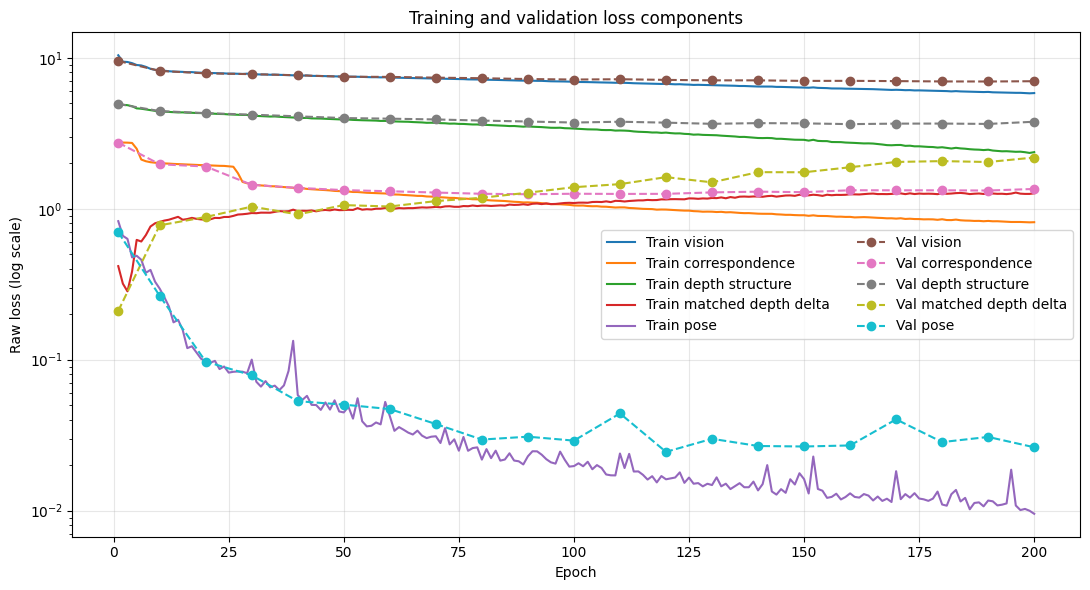

In [17]:
epochs = np.array(history["epoch"])
val_epochs = np.array(history["val_epoch"])
forest_epochs = np.array(history["forest_epoch"])

plt.figure(figsize=(11, 6))

# Train
plt.plot(history["epoch"], history["vision"], label="Train vision")
plt.plot(history["epoch"], history["correspondence"], label="Train correspondence")
plt.plot(history["epoch"], history["depth_structure"], label="Train depth structure")
plt.plot(history["epoch"], history["depth_delta"], label="Train matched depth delta")
plt.plot(history["epoch"], history["pose"], label="Train pose")


# Validation
plt.plot(history["val_epoch"], history["val_vision"], "o--", label="Val vision")
plt.plot(history["val_epoch"], history["val_correspondence"], "o--", label="Val correspondence")
plt.plot(history["val_epoch"], history["val_depth_structure"], "o--", label="Val depth structure")
plt.plot(history["val_epoch"], history["val_depth_delta"], "o--", label="Val matched depth delta")
plt.plot(history["val_epoch"], history["val_pose"], "o--", label="Val pose")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Raw loss (log scale)")
plt.title("Training and validation loss components")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


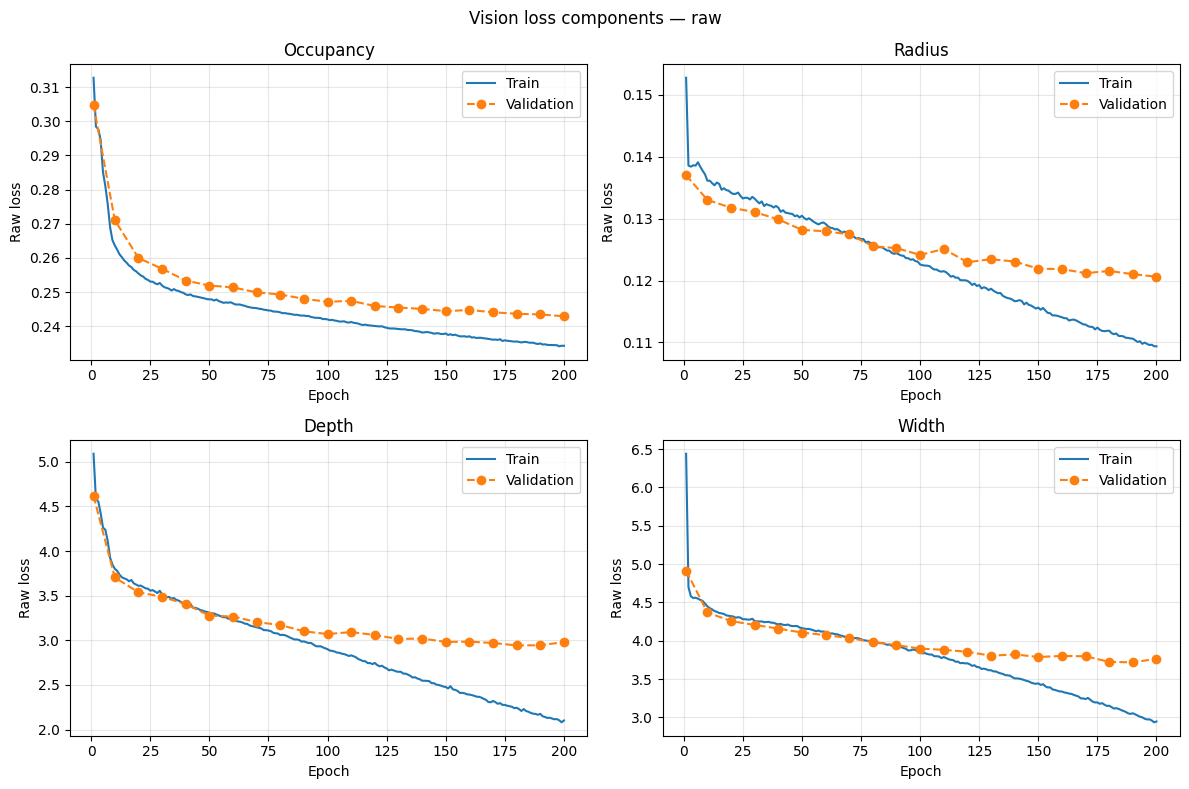

In [26]:
# Separate vision-loss components. False = raw losses; True = actual
# weighted contributions to vision_loss (weights recorded at each epoch).
PLOT_WEIGHTED_VISION = False
suffix = "_weighted" if PLOT_WEIGHTED_VISION else ""
components = [
    ("vision_occupancy", "Occupancy"),
    ("vision_radius", "Radius"),
    ("vision_depth", "Depth"),
    ("vision_width", "Width"),
]
train_epochs = np.asarray(history.get("epoch", []))
validation_epochs = np.asarray(history.get("val_epoch", []))

available = any(
    np.isfinite(np.asarray(history.get(prefix + key + suffix, []), dtype=float)).any()
    for key, _ in components for prefix in ("", "val_")
)
if available:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (key, label) in zip(axes.flat, components):
        for prefix, xs, style, legend in (
            ("", train_epochs, "-", "Train"),
            ("val_", validation_epochs, "o--", "Validation"),
        ):
            values = np.asarray(history.get(prefix + key + suffix, []), dtype=float)
            if len(values) == len(xs) and np.isfinite(values).any():
                ax.plot(xs, values, style, label=legend)
        ax.set_title(label)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Weighted contribution" if PLOT_WEIGHTED_VISION else "Raw loss")
        ax.grid(True, alpha=0.3)
        if ax.lines:
            ax.legend()
    fig.suptitle("Vision loss components — " + ("weighted" if PLOT_WEIGHTED_VISION else "raw"))
    plt.tight_layout()
    plt.show()
else:
    print("This history has no separate vision components yet. They are recorded from the next training epoch.")


## Inference on test data

In [29]:
# Choose the model used for test/inference:
# "best"   -> checkpoint with lowest validation loss
# "latest" -> weights from the final training epoch
INFERENCE_MODEL = INFERENCE_MODEL.lower()
print(f"INFERENCE_MODEL: {INFERENCE_MODEL}")

if INFERENCE_MODEL not in {"best", "latest"}:
    raise ValueError("INFERENCE_MODEL must be either 'best' or 'latest'")

target_model = model._orig_mod if hasattr(model, "_orig_mod") else model

if INFERENCE_MODEL == "best":
    checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
    target_model.load_state_dict(checkpoint["model_state_dict"])

    best_loss = checkpoint.get("best_val_loss")
    if best_loss is not None:
        print(
            f"Using BEST model from epoch {checkpoint.get('best_epoch', checkpoint.get('epoch'))} "
            f"with val_total={best_loss:.6f}"
        )
    else:
        print(f"Using BEST model from epoch {checkpoint.get('epoch', 'unknown')}")
else:
    target_model.load_state_dict(latest_model_state_dict)
    print(f"Using LATEST model from epoch {NUM_EPOCHS}")

model.eval()

infer_dataset = SceneTwoPairsDataset(
    root_dir="testdataset",
    return_two_pairs=False,
)
infer_loader = DataLoader(
    infer_dataset,
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

batch = next(iter(infer_loader))
img_a, vision_a, img_b, vision_b, pose_ab = batch

img_a = img_a.to(device)
vision_a = vision_a.to(device)
img_b = img_b.to(device)
vision_b = vision_b.to(device)
pose_ab = pose_ab.to(device)

with torch.no_grad():
    pred_vision, pred_vision_b, pred_pose, pose_info = model(
        img_a, img_b, target_vision_a=vision_a, target_vision_b=vision_b,
        return_pose_inputs=True, occ_thresh=OCC_THRESH,
    )



INFERENCE_MODEL: latest
Using LATEST model from epoch 200


## Vision prediction plots

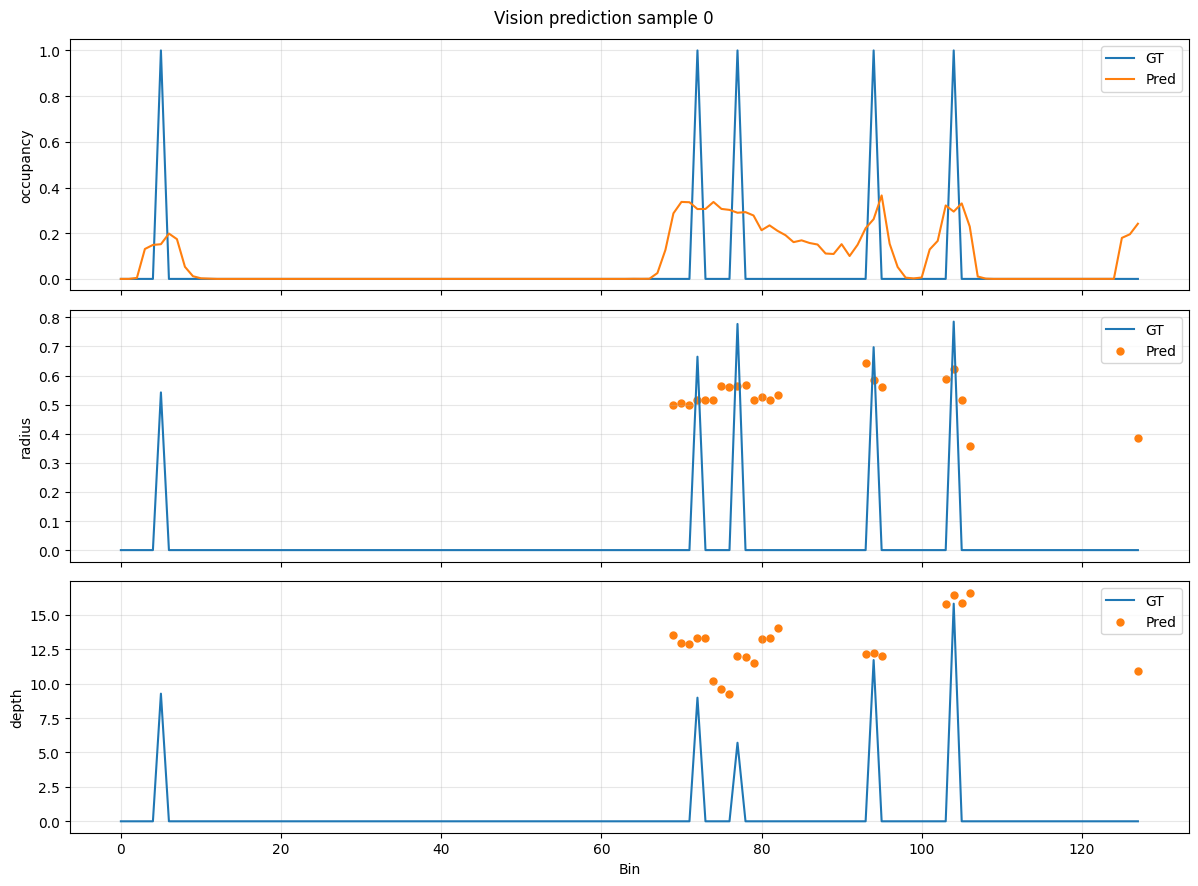

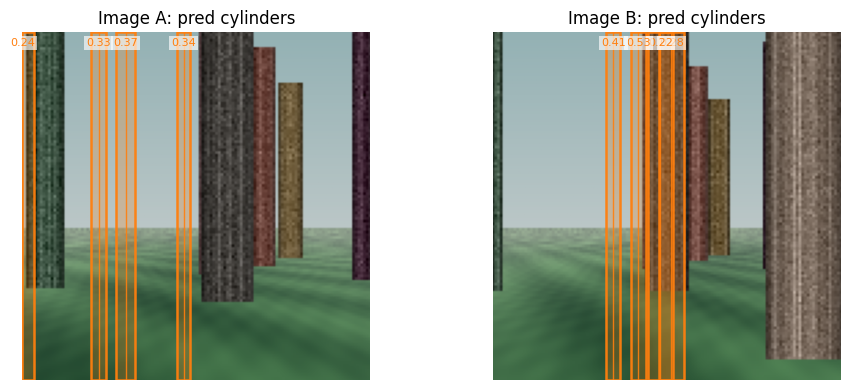

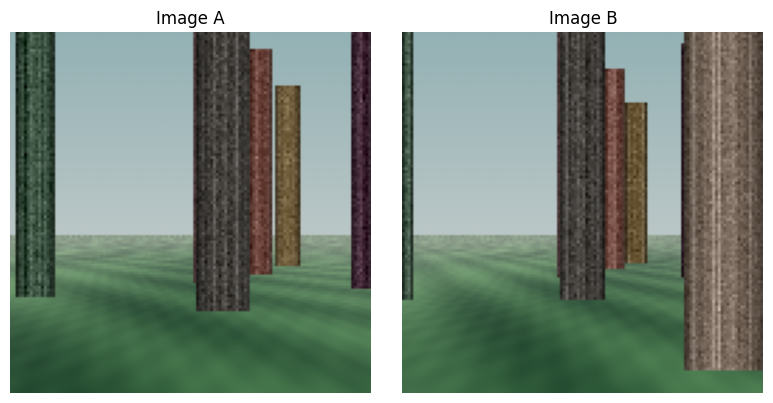

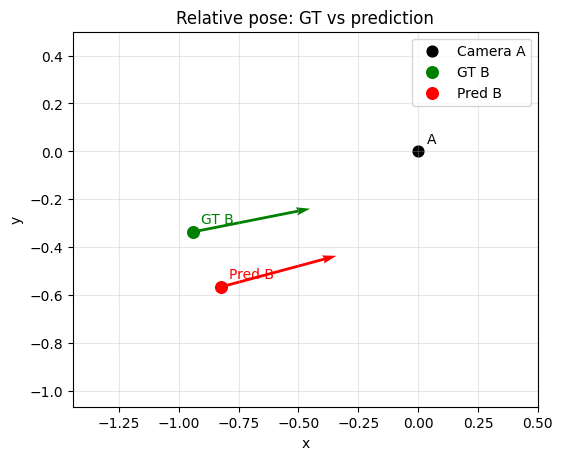

In [30]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(pred_vision.shape[1])
PLOT_OCC_THRESHOLD = 0.2

if INFERENCE_SHOW_IMAGES:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]

    gt_occ = vision_a[sample_idx, :, 0].detach().cpu().numpy()
    pr_occ = pred_vision[sample_idx, :, 0].detach().cpu().numpy()

    for j, ax in enumerate(axes):
        gt = vision_a[sample_idx, :, j].detach().cpu().numpy()
        pr = pred_vision[sample_idx, :, j].detach().cpu().numpy()

        ax.plot(bins, gt, label="GT", color="tab:blue")

        if j == 0:
            ax.plot(bins, pr, label="Pred", color="tab:orange")
        else:
            pr_mask = pr_occ > PLOT_OCC_THRESHOLD
            ax.scatter( bins[pr_mask], pr[pr_mask], label="Pred", color="tab:orange", s=25, )

        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"Vision prediction sample {sample_idx}")
    plt.tight_layout()
    plt.show()

    fig_cyl, axes_cyl = plot_estimated_cylinders_on_images(
        [img_a[sample_idx], img_b[sample_idx]],
        [pred_vision[sample_idx], pred_vision_b[sample_idx]],
        titles=["Image A: pred cylinders", "Image B: pred cylinders"],
        occ_threshold=PLOT_OCC_THRESHOLD,
        flip_x=True,
    )
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[sample_idx].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[sample_idx].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    if pose_info["pose_valid"][sample_idx] and pose_ab[sample_idx, :2].norm() > 1e-6:
        plot_relative_pose(pose_ab[sample_idx], pred_pose[sample_idx])
    else:
        print("Selected sample has no evaluable pose; choose another VISION_SAMPLE_IDX.")


In [31]:
from metrics import evaluate_vision

vision_metrics = evaluate_vision(model, infer_loader, device,  occ_threshold=0.2)


VISION PERFORMANCE

OCCUPANCY, occ_threshold=0.20
------------------------------------------------------------------------------
  Accuracy   Precision    Recall        F1   Recall ±1   Recall ±2
     0.853       0.276     0.415     0.332       0.541       0.596

GEOMETRY
------------------------------------------------------------------------------
                 N       MAE      RMSE      Bias      Corr  Pred std    GT std
Radius       11870     0.122     0.151    -0.003     0.401     0.097     0.161
Depth        11870     2.858     4.122    -0.534     0.669     4.413     5.395

TOLERANCE ACCURACY
------------------------------------------------------------------------------
Radius         ±0.05 m     ±0.10 m     ±0.20 m
                 0.248       0.477       0.803

Depth           ±0.5 m      ±1.0 m      ±2.0 m      ±5.0 m
                 0.177       0.323       0.530       0.815


In [32]:
from metrics import evaluate_pose

pose_metrics = evaluate_pose(model, infer_loader, device)

CAMERA POSE PERFORMANCE
Pose method:            Learned pose with GT matches

Test pairs:             514
Successful poses:       514
Prediction failures:    0
Success rate:           1.000
Excluded GT pairs:      13

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   8.53°
Median:                 4.33°
P90:                    19.27°

YAW ERROR
----------------------------------------
Mean:                   0.85°
Median:                 0.49°
P90:                    1.91°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T= 54.7% | Yaw= 99.2%
< 10°: T= 74.5% | Yaw=100.0%
< 20°: T= 90.5% | Yaw=100.0%
< 30°: T= 95.7% | Yaw=100.0%


## Forest visualization

In [23]:
if FOREST_ENABLED:
    forest_sample_idx = FOREST_SAMPLE_IDX
    model.eval()
    forest_batch = next(iter(forest_loader))
    img_a_forest, img_b_forest, _ = forest_batch

    img_a_forest = img_a_forest.to(device)
    img_b_forest = img_b_forest.to(device)

    with torch.no_grad():
        pred_vision_a_forest, pred_vision_b_forest, pred_pose_forest = model(img_a_forest, img_b_forest, compute_pose=False)

    fig_forest_cyl, axes_forest_cyl = plot_estimated_cylinders_on_images(
        [
            img_a_forest[forest_sample_idx],
            img_b_forest[forest_sample_idx],
        ],
        [
            pred_vision_a_forest[forest_sample_idx],
            pred_vision_b_forest[forest_sample_idx],
        ],
        titles=["Forest A: pred cylinders", "Forest B: pred cylinders"],
        occ_threshold=FOREST_OCC_THRESHOLD,
        flip_x=True,
    )
    plt.show()

    print("forest pred_vision_a shape:", pred_vision_a_forest.shape)
    print("Forest visualization is vision only: no GT bin matches are available.")


## Notes

- Original 27-cell layout, inline training loop, history names and plotting sections are retained.
- The joint model receives GT bin matches; pose uses predicted radius/depth.
- Training starts from scratch with seed 0. `RESUME_TRAINING` only resumes a compatible joint-notebook checkpoint.
- Loss terms/default weights match the current `train_pose.py`, including `LAMBDA_POSE=2.0` and `LAMBDA_DEPTH_DELTA=0.35`.
- Defaults are 100 epochs and 8 data workers, as in that script. Paths remain local like the original notebook.
- Validation is at epoch 1 and every `VAL_INTERVAL`; best selection uses total validation loss.
- Forest is optional visualization only. No separate geometric consistency loss is active.
- `INFERENCE_MODEL` selects best or latest weights for the original inference cells.


In [24]:
import torch
import numpy as np

@torch.no_grad()
def evaluate_depth(loader, name="VALIDATION", occ_threshold=0.5):
    model.eval()

    pred_all = []
    gt_all = []

    for batch in loader:
        if len(batch) == 5:
            img_a, vision_a, img_b, vision_b, _ = batch

            img_a = img_a.to(device, non_blocking=True)
            img_b = img_b.to(device, non_blocking=True)
            vision_a = vision_a.to(device, non_blocking=True)
            vision_b = vision_b.to(device, non_blocking=True)

            pred_a, pred_b, _ = model(img_a, img_b, compute_pose=False)

            for pred, gt in [(pred_a, vision_a), (pred_b, vision_b)]:
                mask = gt[..., 0] > occ_threshold
                pred_all.append(pred[..., 2][mask].detach().cpu())
                gt_all.append(gt[..., 2][mask].detach().cpu())

        elif len(batch) == 10:
            img_a1, vision_a1, img_b1, vision_b1, _, img_a2, vision_a2, img_b2, vision_b2, _ = batch

            pairs = [
                (img_a1, vision_a1, img_b1, vision_b1),
                (img_a2, vision_a2, img_b2, vision_b2),
            ]

            for img_a, vision_a, img_b, vision_b in pairs:
                img_a = img_a.to(device, non_blocking=True)
                img_b = img_b.to(device, non_blocking=True)
                vision_a = vision_a.to(device, non_blocking=True)
                vision_b = vision_b.to(device, non_blocking=True)

                pred_a, pred_b, _ = model(img_a, img_b, compute_pose=False)

                for pred, gt in [(pred_a, vision_a), (pred_b, vision_b)]:
                    mask = gt[..., 0] > occ_threshold
                    pred_all.append(pred[..., 2][mask].detach().cpu())
                    gt_all.append(gt[..., 2][mask].detach().cpu())

        else:
            raise ValueError(f"Okänt batch-format: {len(batch)}")

    pred = torch.cat(pred_all).float()
    gt = torch.cat(gt_all).float()

    abs_err = (pred - gt).abs()
    rel_err = abs_err / (gt.abs() + 1e-6)

    mae = abs_err.mean().item()
    rmse = torch.sqrt(((pred - gt) ** 2).mean()).item()
    median_ae = abs_err.median().item()
    rel_mae = rel_err.mean().item()
    median_rel = rel_err.median().item()

    pred_centered = pred - pred.mean()
    gt_centered = gt - gt.mean()
    corr = (
        (pred_centered * gt_centered).mean()
        / (pred_centered.std() * gt_centered.std() + 1e-8)
    ).item()

    baseline = (gt - gt.mean()).abs().mean().item()

    print(f"\n{name}")
    print("-" * 45)
    print(f"Occupied bins:        {len(gt)}")
    print(f"GT depth mean:        {gt.mean().item():.3f}")
    print(f"GT depth std:         {gt.std().item():.3f}")
    print(f"Pred depth mean:      {pred.mean().item():.3f}")
    print(f"Pred depth std:       {pred.std().item():.3f}")
    print(f"Depth MAE:            {mae:.3f}")
    print(f"Depth RMSE:           {rmse:.3f}")
    print(f"Median abs error:     {median_ae:.3f}")
    print(f"Relative MAE:         {100 * rel_mae:.1f}%")
    print(f"Median relative err:  {100 * median_rel:.1f}%")
    print(f"Depth correlation:    {corr:.3f}")
    print(f"Mean-depth baseline:  {baseline:.3f}")
    print(f"Improvement baseline: {baseline / max(mae, 1e-8):.2f}x")